In [ ]:
'''Implement and evaluate an XGBoost model for predictive analysis, focusing on regularization techniques and 
early stopping to prevent overfitting on complex applicant data'''

In [1]:

# import libraries required for xgboost and model evaluation

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from xgboost import XGBRegressor

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("all libraries imported successfully")


all libraries imported successfully


In [3]:

# load the university admission dataset

df = pd.read_csv("Adm.csv")

print("dataset loaded successfully")
print("dataset shape:", df.shape)

df.head()


dataset loaded successfully
dataset shape: (1000, 12)


,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,Application_DateTime,University_Name,region
0,1,337,118,4,4.5,4.5,9.65,1,0.92,2022-01-01 09:00:00,Indian Institute of Technology Kharagpur,East
1,2,324,107,4,4.0,4.5,8.87,1,0.76,2022-01-02 09:00:00,National Institute of Technology Karnataka,South
2,3,316,104,3,3.0,3.5,8.00,1,0.72,2022-01-04 09:00:00,Gujarat University,West
3,4,322,110,3,3.5,2.5,8.67,1,0.80,2022-01-06 09:00:00,Jamia Millia Islamia,North
4,5,314,103,2,2.0,3.0,8.21,0,0.65,2022-01-08 09:00:00,Jamia Millia Islamia,North


In [4]:

# understand the dataset columns and check missing values

print("dataset columns:")
print(df.columns.tolist())

print("\ndataset information:")
df.info()

print("\nmissing values:")
print(df.isnull().sum())

print("\nstatistical summary:")
df.describe(include="all")


dataset columns:
['Serial No.', 'GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research', 'Chance of Admit', 'Application_DateTime', 'University_Name', 'region']

dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Serial No.            1000 non-null   int64  
 1   GRE Score             1000 non-null   int64  
 2   TOEFL Score           1000 non-null   int64  
 3   University Rating     1000 non-null   int64  
 4   SOP                   1000 non-null   float64
 5   LOR                   1000 non-null   float64
 6   CGPA                  1000 non-null   float64
 7   Research              1000 non-null   int64  
 8   Chance of Admit       1000 non-null   float64
 9   Application_DateTime  1000 non-null   object 
 10  University_Name       1000 non-null   object 
 11  region           

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,Application_DateTime,University_Name,region
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1000.00000,1000,1000,1000
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1000,49,6
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2022-01-01 09:00:00,National Institute of Technology Warangal,South
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,32,379
mean,500.500000,315.965000,106.564000,3.015000,3.393500,3.406700,8.58979,0.503000,0.71777,NaN,NaN,NaN
std,288.819436,13.415653,7.634277,1.317768,1.027279,0.891864,0.61217,0.500241,0.14591,NaN,NaN,NaN
min,1.000000,290.000000,92.000000,1.000000,0.900000,0.900000,6.77000,0.000000,0.32000,NaN,NaN,NaN
25%,250.750000,305.000000,101.000000,2.000000,2.500000,3.000000,8.18000,0.000000,0.63750,NaN,NaN,NaN
50%,500.500000,316.000000,107.000000,3.000000,3.500000,3.500000,8.58000,1.000000,0.72000,NaN,NaN,NaN
75%,750.250000,326.250000,113.000000,4.000000,4.000000,4.000000,9.07000,1.000000,0.82000,NaN,NaN,NaN


In [5]:

# clean unnecessary columns and extract useful application date information

df["Application_DateTime"] = pd.to_datetime(
    df["Application_DateTime"],
    errors="coerce"
)

df["Application_Year"] = df["Application_DateTime"].dt.year
df["Application_Month"] = df["Application_DateTime"].dt.month

df.drop(
    columns=["Serial No.", "Application_DateTime"],
    inplace=True
)

print("data cleaning completed")

df.head()


data cleaning completed


,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,University_Name,region,Application_Year,Application_Month
0,337,118,4,4.5,4.5,9.65,1,0.92,Indian Institute of Technology Kharagpur,East,2022,1
1,324,107,4,4.0,4.5,8.87,1,0.76,National Institute of Technology Karnataka,South,2022,1
2,316,104,3,3.0,3.5,8.00,1,0.72,Gujarat University,West,2022,1
3,322,110,3,3.5,2.5,8.67,1,0.80,Jamia Millia Islamia,North,2022,1
4,314,103,2,2.0,3.0,8.21,0,0.65,Jamia Millia Islamia,North,2022,1


In [6]:

# separate applicant details and admission chance for prediction

X = df.drop(columns=["Chance of Admit"])
y = df["Chance of Admit"]

print("input features:", X.shape)
print("target values:", y.shape)

print("\ninput columns:")
print(X.columns.tolist())

print("\nadmission chance range:")
print(y.min(), "to", y.max())


input features: (1000, 11)
target values: (1000,)

input columns:
['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research', 'University_Name', 'region', 'Application_Year', 'Application_Month']

admission chance range:
0.32 to 0.97


In [7]:

# identify numerical and categorical applicant information

numeric_cols = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_cols = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("numerical features:")
print(numeric_cols)

print("\ncategorical features:")
print(categorical_cols)


numerical features:
['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research', 'Application_Year', 'Application_Month']

categorical features:
['University_Name', 'region']


In [8]:

# handle missing values and convert applicant information into model-ready format

preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numeric_cols),

        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_cols)
    ]
)

print("preprocessing pipeline created successfully")


preprocessing pipeline created successfully


In [9]:

# divide data into training validation and testing sets

X_temp, X_test, y_temp, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.20,
    random_state=42
)

print("training records:", len(X_train))
print("validation records:", len(X_val))
print("testing records:", len(X_test))


training records: 640
validation records: 160
testing records: 200


In [10]:

# apply preprocessing using training data and transform validation and testing data

X_train_processed = preprocessor.fit_transform(X_train)

X_val_processed = preprocessor.transform(X_val)

X_test_processed = preprocessor.transform(X_test)

print("training data:", X_train_processed.shape)
print("validation data:", X_val_processed.shape)
print("testing data:", X_test_processed.shape)

print("data preprocessing completed")


training data: (640, 64)
validation data: (160, 64)
testing data: (200, 64)
data preprocessing completed


In [11]:

# create xgboost model with regularization to control overfitting

xgb_model = XGBRegressor(
    n_estimators=1000,
    learning_rate=0.03,
    max_depth=4,

    # regularization settings
    reg_alpha=0.1,
    reg_lambda=5,
    gamma=0.1,

    # sampling settings
    subsample=0.8,
    colsample_bytree=0.8,

    # model settings
    objective="reg:squarederror",
    eval_metric="rmse",
    random_state=42,
    early_stopping_rounds=50,
    n_jobs=-1
)

print("xgboost model created with regularization")


xgboost model created with regularization


In [12]:

# train xgboost and stop when validation performance stops improving

xgb_model.fit(
    X_train_processed,
    y_train,

    eval_set=[
        (X_train_processed, y_train),
        (X_val_processed, y_val)
    ],

    verbose=False
)

print("xgboost training completed")

print("best iteration:", xgb_model.best_iteration)
print("best validation rmse:", round(
    xgb_model.best_score, 5
))


xgboost training completed
best iteration: 119
best validation rmse: 0.12897


In [13]:

# predict admission chances for unseen applicant records

y_pred = xgb_model.predict(X_test_processed)

print("admission predictions completed")

prediction_df = pd.DataFrame({
    "actual_chance": y_test.values[:10],
    "predicted_chance": y_pred[:10]
})

prediction_df["predicted_chance"] = (
    prediction_df["predicted_chance"].round(3)
)

prediction_df


admission predictions completed


,actual_chance,predicted_chance
0,0.79,0.724
1,0.91,0.691
2,0.65,0.707
3,0.92,0.786
4,0.88,0.729
5,0.59,0.709
6,0.65,0.674
7,0.54,0.742
8,0.83,0.680
9,0.76,0.692


In [14]:

# calculate regression performance metrics on testing data

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

performance = pd.DataFrame({
    "evaluation metric": [
        "mean absolute error",
        "mean squared error",
        "root mean squared error",
        "r2 score"
    ],

    "result": [
        mae,
        mse,
        rmse,
        r2
    ]
})

print("xgboost model performance:")
print(performance.round(4).to_string(index=False))


xgboost model performance:
      evaluation metric  result
    mean absolute error  0.0854
     mean squared error  0.0130
root mean squared error  0.1139
               r2 score  0.2430


In [15]:

# compare training and testing errors to check overfitting

train_pred = xgb_model.predict(X_train_processed)

train_rmse = np.sqrt(
    mean_squared_error(y_train, train_pred)
)

test_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

comparison = pd.DataFrame({
    "dataset": ["training", "testing"],
    "rmse": [train_rmse, test_rmse],
    "r2_score": [
        r2_score(y_train, train_pred),
        r2_score(y_test, y_pred)
    ]
})

print("training vs testing performance:")
print(comparison.round(4).to_string(index=False))


training vs testing performance:
 dataset   rmse  r2_score
training 0.1222    0.3319
 testing 0.1139    0.2430


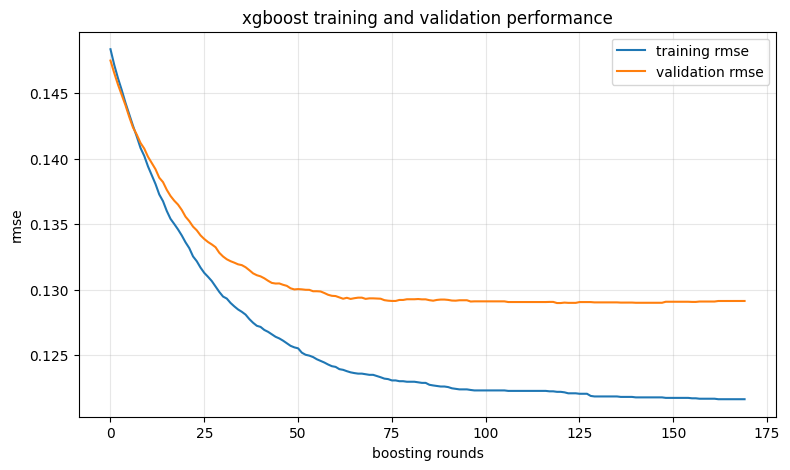

In [16]:

# visualize model learning and observe validation error during training

results = xgb_model.evals_result()

plt.figure(figsize=(9, 5))

plt.plot(
    results["validation_0"]["rmse"],
    label="training rmse"
)

plt.plot(
    results["validation_1"]["rmse"],
    label="validation rmse"
)

plt.xlabel("boosting rounds")
plt.ylabel("rmse")
plt.title("xgboost training and validation performance")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


top 10 important features:
                                              feature  importance
5                                           num__CGPA    0.140447
1                                    num__TOEFL Score    0.116420
7                               num__Application_Year    0.111592
6                                       num__Research    0.087229
2                              num__University Rating    0.085460
0                                      num__GRE Score    0.081648
4                                            num__LOR    0.075411
62                                  cat__region_South    0.070714
3                                            num__SOP    0.068144
27  cat__University_Name_Indian Institute of Techn...    0.056110


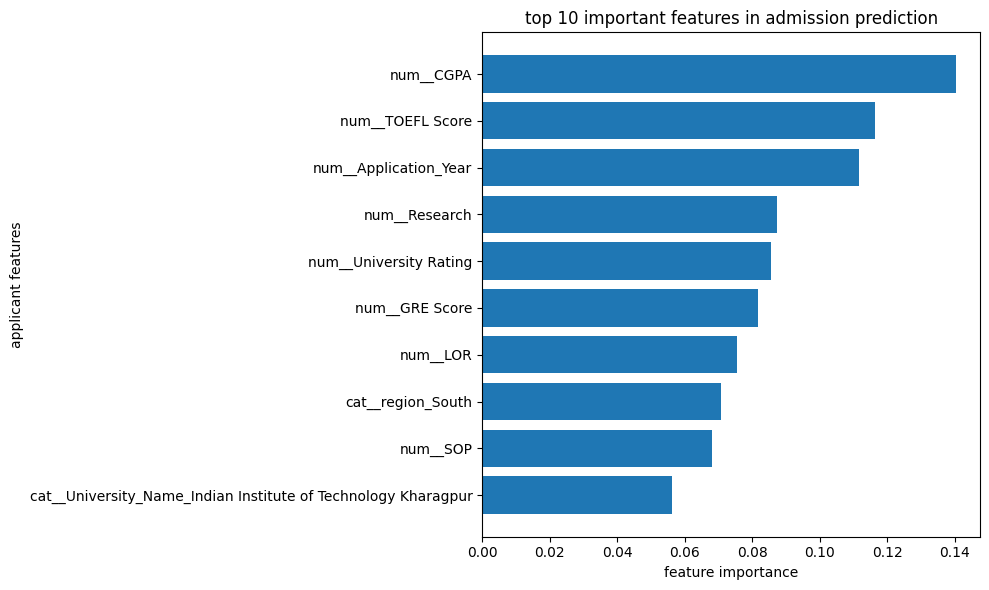

In [17]:

# identify which applicant features contribute most to admission prediction

feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": xgb_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="importance",
    ascending=False
)

print("top 10 important features:")
print(importance_df.head(10))

plt.figure(figsize=(10, 6))

top_features = importance_df.head(10).sort_values(
    by="importance"
)

plt.barh(
    top_features["feature"],
    top_features["importance"]
)

plt.xlabel("feature importance")
plt.ylabel("applicant features")
plt.title("top 10 important features in admission prediction")
plt.tight_layout()
plt.show()


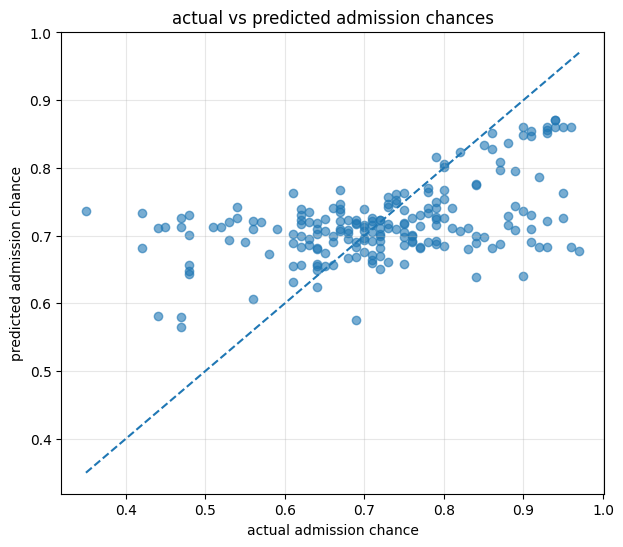

In [18]:

# compare actual admission chances with predicted admission chances

plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.6
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("actual admission chance")
plt.ylabel("predicted admission chance")
plt.title("actual vs predicted admission chances")
plt.grid(alpha=0.3)
plt.show()


In [19]:

# display final xgboost model results and regularization settings



print("model: xgboost regressor")
print("best boosting iteration:", xgb_model.best_iteration)

print("\nregularization:")
print("l1 regularization:", xgb_model.get_params()["reg_alpha"])
print("l2 regularization:", xgb_model.get_params()["reg_lambda"])
print("gamma:", xgb_model.get_params()["gamma"])

print("\nperformance:")
print("mae:", round(mae, 4))
print("mse:", round(mse, 4))
print("rmse:", round(rmse, 4))
print("r2 score:", round(r2, 4))

print("\ntraining rmse:", round(train_rmse, 4))
print("testing rmse:", round(test_rmse, 4))

print("\nxgboost model evaluation completed")


model: xgboost regressor
best boosting iteration: 119

regularization:
l1 regularization: 0.1
l2 regularization: 5
gamma: 0.1

performance:
mae: 0.0854
mse: 0.013
rmse: 0.1139
r2 score: 0.243

training rmse: 0.1222
testing rmse: 0.1139

xgboost model evaluation completed
